# Customer Segmentation: RFM, K-Means, SQL & Tableau
## Remaining phases of the A/B Testing and Customer Segmentation project

This notebook continues from your first notebook. It uses the Online Retail dataset only. The marketing A/B test dataset is separate and must not be joined to retail customers.

**Deliverables:** RFM customer table, RFM scores and segments, K-Means clusters, model evaluation charts, SQL database and queries, Tableau-ready CSVs, data dictionary and a project summary.

## 1. Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Set paths and import libraries

In [23]:
from pathlib import Path
import os, json, sqlite3, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from google.colab import files

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Same Drive folder used in the first notebook.
PROJECT_DIR = Path("/content/drive/MyDrive/AB testing")
OUTPUT_DIR = PROJECT_DIR / "phase_4_to_6_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLEANED_CSV = PROJECT_DIR / "outputs" / "online_retail_positive_sales_clean.csv"
ORIGINAL_XLSX = PROJECT_DIR / "Online Retail.xlsx"

RANDOM_STATE = 42
MIN_K, MAX_K = 2, 8

print("Project folder:", PROJECT_DIR)
print("Cleaned CSV found:", CLEANED_CSV.exists())
print("Original Excel found:", ORIGINAL_XLSX.exists())
if not CLEANED_CSV.exists() and not ORIGINAL_XLSX.exists():
    raise FileNotFoundError(
        "Could not find the cleaned CSV or Online Retail.xlsx. "
        "Place one in My Drive/AB testing or change PROJECT_DIR."
    )

Project folder: /content/drive/MyDrive/AB testing
Cleaned CSV found: False
Original Excel found: True


## 3. Load and validate the Online Retail data

In [24]:
if CLEANED_CSV.exists():
    retail = pd.read_csv(CLEANED_CSV)
    print("Loaded cleaned sales CSV.")
else:
    retail = pd.read_excel(ORIGINAL_XLSX)
    print("Loaded original Excel file.")

retail.columns = [str(c).strip() for c in retail.columns]
required = ["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "CustomerID"]
missing = [c for c in required if c not in retail.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

retail["InvoiceDate"] = pd.to_datetime(retail["InvoiceDate"], errors="coerce")
retail["Quantity"] = pd.to_numeric(retail["Quantity"], errors="coerce")
retail["UnitPrice"] = pd.to_numeric(retail["UnitPrice"], errors="coerce")
retail["CustomerID"] = pd.to_numeric(retail["CustomerID"], errors="coerce")
retail["InvoiceNo"] = retail["InvoiceNo"].astype(str).str.strip()
retail["Revenue"] = retail["Quantity"] * retail["UnitPrice"]
retail = retail.drop_duplicates().copy()

# Consistent positive-sales rules: exclude cancellations, returns, invalid dates,
# missing customer IDs and non-positive unit prices.
retail = retail[
    retail["InvoiceDate"].notna()
    & retail["CustomerID"].notna()
    & (~retail["InvoiceNo"].str.startswith("C"))
    & (retail["Quantity"] > 0)
    & (retail["UnitPrice"] > 0)
].copy()

retail["CustomerID"] = retail["CustomerID"].astype("int64")
retail["Revenue"] = retail["Quantity"] * retail["UnitPrice"]
if "Country" not in retail.columns:
    retail["Country"] = "Unknown"

print("Transaction rows:", f"{len(retail):,}")
print("Unique customers:", f"{retail['CustomerID'].nunique():,}")
print("Unique invoices:", f"{retail['InvoiceNo'].nunique():,}")
print("Date range:", retail["InvoiceDate"].min(), "to", retail["InvoiceDate"].max())
print("Positive-sales revenue: GBP", f"{retail['Revenue'].sum():,.2f}")
display(retail.head())

Loaded original Excel file.
Transaction rows: 392,692
Unique customers: 4,338
Unique invoices: 18,532
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Positive-sales revenue: GBP 8,887,208.89


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,17850,United Kingdom,15.300
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,17850,United Kingdom,20.340
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,17850,United Kingdom,22.000
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,17850,United Kingdom,20.340
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,17850,United Kingdom,20.340


## 4. RFM analysis

- **Recency:** days since the customer's most recent purchase. Lower is better.
- **Frequency:** number of distinct invoices/orders. Higher is generally better.
- **Monetary:** total sales revenue generated by the customer. Higher is generally better.

The snapshot date is one day after the latest transaction date.

In [25]:
snapshot_date = retail["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = retail.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    Country=("Country", lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown"),
    TransactionRows=("InvoiceNo", "size")
).reset_index()

rfm = rfm[
    (rfm["Recency"] >= 0) & (rfm["Frequency"] > 0) & (rfm["Monetary"] > 0)
].copy()
rfm["AverageOrderValue"] = rfm["Monetary"] / rfm["Frequency"]

print("Snapshot date:", snapshot_date.date())
print("Customers in RFM table:", f"{len(rfm):,}")
display(rfm.head())
display(rfm[["Recency", "Frequency", "Monetary", "AverageOrderValue"]].describe().T)

Snapshot date: 2011-12-10
Customers in RFM table: 4,338


,CustomerID,Recency,Frequency,Monetary,FirstPurchase,LastPurchase,Country,TransactionRows,AverageOrderValue
0,12346,326,1,"77,183.600",2011-01-18 10:01:00,2011-01-18 10:01:00,United Kingdom,1,"77,183.600"
1,12347,3,7,"4,310.000",2010-12-07 14:57:00,2011-12-07 15:52:00,Iceland,182,615.714
2,12348,76,4,"1,797.240",2010-12-16 19:09:00,2011-09-25 13:13:00,Finland,31,449.310
3,12349,19,1,"1,757.550",2011-11-21 09:51:00,2011-11-21 09:51:00,Italy,73,"1,757.550"
4,12350,311,1,334.400,2011-02-02 16:01:00,2011-02-02 16:01:00,Norway,17,334.400


,count,mean,std,min,25%,50%,75%,max
Recency,"4,338.000",93.059,100.012,1.000,18.000,51.000,142.750,374.000
Frequency,"4,338.000",4.272,7.698,1.000,1.000,2.000,5.000,209.000
Monetary,"4,338.000","2,048.688","8,985.230",3.750,306.482,668.570,"1,660.597","280,206.020"
AverageOrderValue,"4,338.000",417.646,"1,796.511",3.450,177.867,291.940,428.281,"84,236.250"


## 5. Explore RFM distributions and outliers

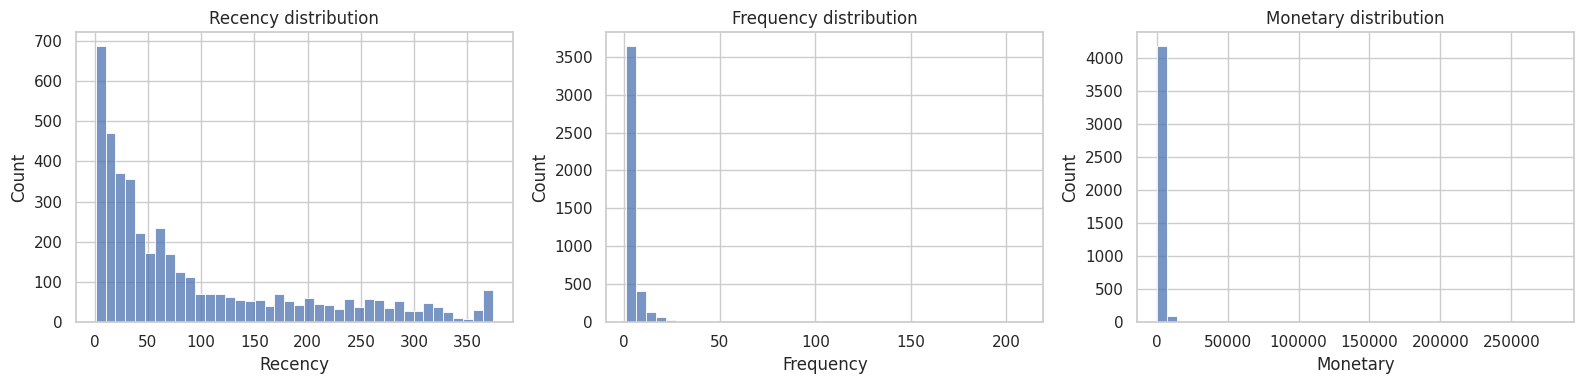

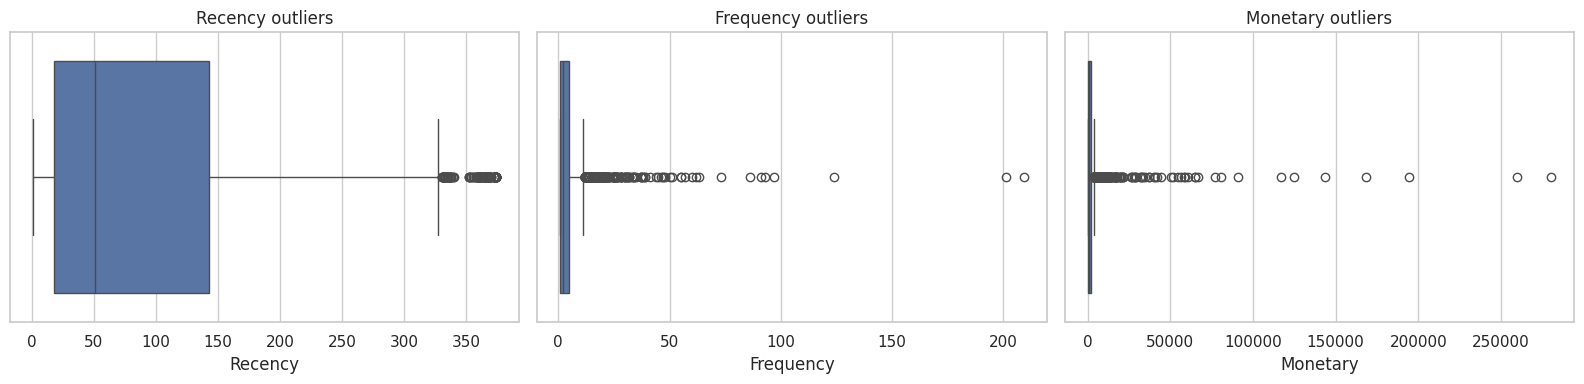

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"{col} distribution")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rfm_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(x=rfm[col], ax=ax)
    ax.set_title(f"{col} outliers")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rfm_boxplots.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. RFM quintile scoring

Scores range from 1 to 5. Recency is reversed because fewer days since the last purchase is better. Frequency and Monetary scores increase with their values.

These scores create transparent business segments. K-Means is performed separately below.

In [27]:
def quintile_score(series, higher_is_better=True):
    # Rank first to handle tied values safely before qcut.
    ranks = series.rank(method="first", ascending=True)
    score = pd.qcut(ranks, 5, labels=[1, 2, 3, 4, 5]).astype(int)
    return score if higher_is_better else 6 - score

rfm["R_Score"] = quintile_score(rfm["Recency"], higher_is_better=False)
rfm["F_Score"] = quintile_score(rfm["Frequency"], higher_is_better=True)
rfm["M_Score"] = quintile_score(rfm["Monetary"], higher_is_better=True)
rfm["RFM_Score"] = rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]

display(rfm[["CustomerID", "Recency", "Frequency", "Monetary",
             "R_Score", "F_Score", "M_Score", "RFM_Score"]].head(10))
print("RFM score range:", rfm["RFM_Score"].min(), "to", rfm["RFM_Score"].max())

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,"77,183.600",1,1,5,7
1,12347,3,7,"4,310.000",5,5,5,15
2,12348,76,4,"1,797.240",2,4,4,10
3,12349,19,1,"1,757.550",4,1,4,9
4,12350,311,1,334.400,1,1,2,4
5,12352,37,8,"2,506.040",3,5,5,13
6,12353,205,1,89.000,1,1,1,3
7,12354,233,1,"1,079.400",1,1,4,6
8,12355,215,1,459.400,1,1,2,4
9,12356,23,3,"2,811.430",4,3,5,12


RFM score range: 3 to 15


## 7. Assign RFM business segments

Rules are based on the RFM quintile scores:
- Champions: high scores across all three dimensions.
- Loyal Customers: recent purchasers with strong frequency.
- Big Spenders: recent customers with high monetary value.
- Potential Loyalists: recent customers with developing purchase frequency.
- At Risk: less recent customers with some historical frequency or spend.
- Hibernating: low recency, frequency and monetary scores.
- Needs Attention: remaining customers.

These are practical analytical definitions for this dataset, not universal definitions.

In [28]:
def assign_rfm_segment(row):
    r, f, m = row["R_Score"], row["F_Score"], row["M_Score"]
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    if r >= 3 and f >= 4:
        return "Loyal Customers"
    if r >= 3 and m >= 4:
        return "Big Spenders"
    if r >= 4 and f >= 2:
        return "Potential Loyalists"
    if r <= 2 and (f >= 3 or m >= 3):
        return "At Risk"
    if r <= 2 and f <= 2 and m <= 2:
        return "Hibernating"
    return "Needs Attention"

rfm["RFM_Segment"] = rfm.apply(assign_rfm_segment, axis=1)

rfm_segment_summary = rfm.groupby("RFM_Segment").agg(
    Customers=("CustomerID", "nunique"),
    Revenue=("Monetary", "sum"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    AvgRFMScore=("RFM_Score", "mean")
).reset_index()

rfm_segment_summary["CustomerSharePct"] = (
    100 * rfm_segment_summary["Customers"] / rfm_segment_summary["Customers"].sum()
)
rfm_segment_summary["RevenueSharePct"] = (
    100 * rfm_segment_summary["Revenue"] / rfm_segment_summary["Revenue"].sum()
)
rfm_segment_summary = rfm_segment_summary.sort_values("Revenue", ascending=False)
display(rfm_segment_summary)

,RFM_Segment,Customers,Revenue,AvgRecency,AvgFrequency,AvgMonetary,AvgRFMScore,CustomerSharePct,RevenueSharePct
2,Champions,941,"5,741,913.580",12.982,11.215,"6,101.927",13.936,21.692,64.609
0,At Risk,911,"1,162,209.822",159.451,2.841,"1,275.752",7.868,21.000,13.077
4,Loyal Customers,504,"918,045.601",37.365,5.119,"1,821.519",11.395,11.618,10.330
1,Big Spenders,204,"508,020.750",33.123,2.324,"2,490.298",10.613,4.703,5.716
5,Needs Attention,586,"211,778.430",44.817,1.341,361.397,6.899,13.509,2.383
3,Hibernating,824,"188,415.281",228.086,1.042,228.659,4.188,18.995,2.120
6,Potential Loyalists,368,"156,825.430",17.448,1.880,426.156,9.125,8.483,1.765


## 8. Visualize RFM segments and revenue contribution

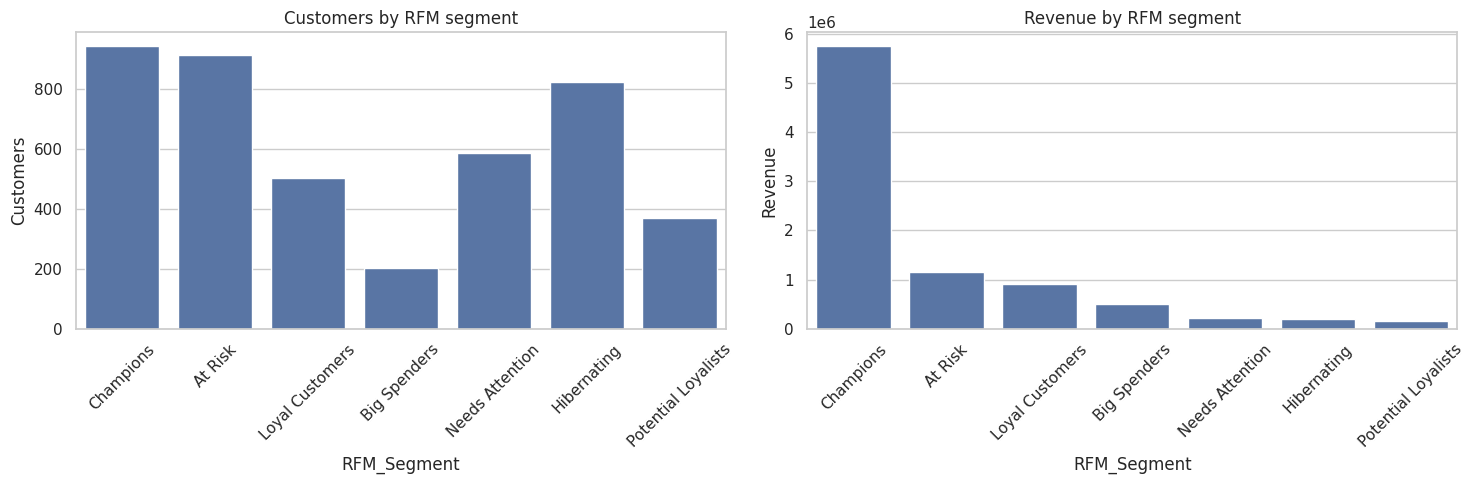

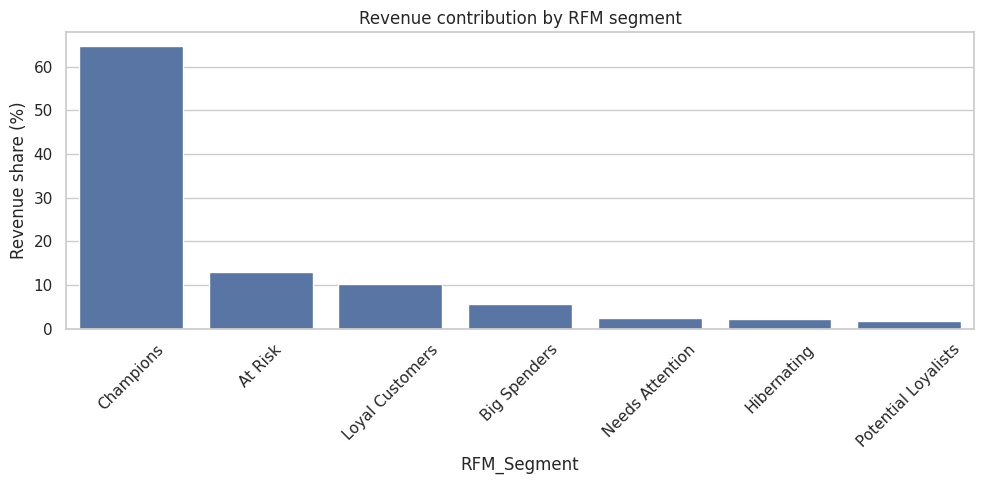

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=rfm_segment_summary, x="RFM_Segment", y="Customers", ax=axes[0])
axes[0].set_title("Customers by RFM segment")
axes[0].tick_params(axis="x", rotation=45)
sns.barplot(data=rfm_segment_summary, x="RFM_Segment", y="Revenue", ax=axes[1])
axes[1].set_title("Revenue by RFM segment")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rfm_segment_performance.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=rfm_segment_summary, x="RFM_Segment", y="RevenueSharePct")
plt.title("Revenue contribution by RFM segment")
plt.ylabel("Revenue share (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rfm_revenue_contribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Prepare features for K-Means

RFM variables are usually right-skewed. We apply `log1p` and then standardize the transformed variables so that Monetary's larger numeric scale does not dominate distance calculations. Original RFM values remain unchanged for interpretation.

In [30]:
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()
rfm_log = np.log1p(rfm_features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

print("Clustering matrix:", X_scaled.shape)
print("Feature means:", np.round(X_scaled.mean(axis=0), 4))
print("Feature standard deviations:", np.round(X_scaled.std(axis=0), 4))

Clustering matrix: (4338, 3)
Feature means: [ 0. -0. -0.]
Feature standard deviations: [1. 1. 1.]


## 10. Choose K: Elbow Method and Silhouette Score

,K,Inertia,SilhouetteScore
0,2,"6,476.507",0.433
1,3,"4,858.078",0.337
2,4,"3,925.274",0.334
3,5,"3,269.075",0.318
4,6,"2,840.654",0.315
5,7,"2,532.985",0.310
6,8,"2,325.075",0.302


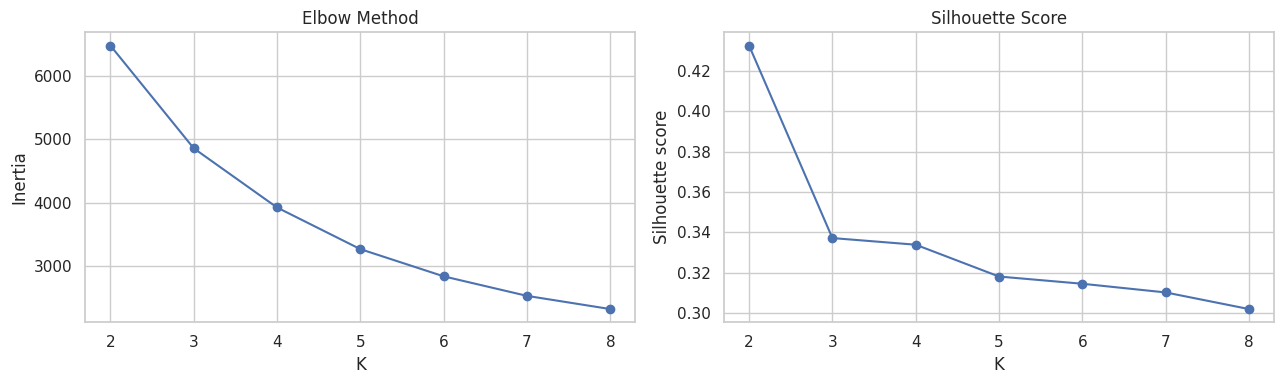

In [31]:
k_values = list(range(MIN_K, min(MAX_K, len(rfm) - 1) + 1))
inertias, silhouettes = [], []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

k_evaluation = pd.DataFrame({
    "K": k_values,
    "Inertia": inertias,
    "SilhouetteScore": silhouettes
})
display(k_evaluation)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_values, silhouettes, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "k_selection_elbow_silhouette.png", dpi=160, bbox_inches="tight")
plt.show()

### K-Means Model Selection and Interpretation

The optimal number of clusters was selected using the Silhouette Score, which evaluates how well-separated and internally consistent the clusters are.

Among the tested values (K = 2 to 8), K = 2 achieved the highest Silhouette Score of 0.4325.

The resulting clusters represent two broad customer groups: relatively recent, frequent and high-value customers, and less active, lower-value customers.

Although K = 2 provides the strongest separation among the tested options, it offers limited granularity for targeted marketing. Therefore, the seven rule-based RFM segments are also retained for more detailed business recommendations.


## 11. Fit the final K-Means model

The default selects the K with the highest silhouette score from the tested range. Review both charts before finalizing: the highest silhouette score is not automatically the most useful business segmentation.

After reviewing the charts, you can set `MANUAL_K` to a selected integer and rerun this cell and the following cells.

In [32]:
MANUAL_K = None  # Example: 4. Keep None to select the highest silhouette score automatically.

if MANUAL_K is None:
    FINAL_K = int(k_evaluation.loc[k_evaluation["SilhouetteScore"].idxmax(), "K"])
else:
    FINAL_K = int(MANUAL_K)
    if FINAL_K not in k_values:
        raise ValueError(f"MANUAL_K must be one of {k_values}")

kmeans = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=30)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)
final_silhouette = silhouette_score(X_scaled, rfm["Cluster"])

print("Selected K:", FINAL_K)
print("Final silhouette score:", round(final_silhouette, 4))
display(rfm[["CustomerID", "Recency", "Frequency", "Monetary", "Cluster"]].head())

Selected K: 2
Final silhouette score: 0.4325


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,"77,183.600",0
1,12347,3,7,"4,310.000",0
2,12348,76,4,"1,797.240",0
3,12349,19,1,"1,757.550",1
4,12350,311,1,334.400,1


## 12. Profile clusters and assign descriptive labels

K-Means cluster IDs are arbitrary. This cell profiles each cluster using the original RFM values and assigns a descriptive name based on relative cluster averages. Review the profile table to ensure the label matches the observed behaviour.

In [33]:
cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "nunique"),
    AvgRecency=("Recency", "mean"),
    MedianRecency=("Recency", "median"),
    AvgFrequency=("Frequency", "mean"),
    MedianFrequency=("Frequency", "median"),
    AvgMonetary=("Monetary", "mean"),
    MedianMonetary=("Monetary", "median"),
    TotalRevenue=("Monetary", "sum"),
    AvgRFMScore=("RFM_Score", "mean")
).reset_index()

cluster_profile["CustomerSharePct"] = (
    100 * cluster_profile["Customers"] / cluster_profile["Customers"].sum()
)
cluster_profile["RevenueSharePct"] = (
    100 * cluster_profile["TotalRevenue"] / cluster_profile["TotalRevenue"].sum()
)

med_r = rfm["Recency"].median()
med_f = rfm["Frequency"].median()
med_m = rfm["Monetary"].median()

def name_cluster(row):
    recent = row["AvgRecency"] <= med_r
    frequent = row["AvgFrequency"] >= med_f
    high_spend = row["AvgMonetary"] >= med_m
    if recent and frequent and high_spend:
        return "Champions"
    if not recent and (frequent or high_spend):
        return "At Risk"
    if recent and frequent:
        return "Loyal Customers"
    if recent and high_spend:
        return "Big Spenders"
    if recent:
        return "Potential Loyalists"
    if frequent or high_spend:
        return "Needs Attention"
    return "Hibernating"

cluster_profile["ClusterSegment"] = cluster_profile.apply(name_cluster, axis=1)
cluster_to_name = dict(zip(cluster_profile["Cluster"], cluster_profile["ClusterSegment"]))
rfm["KMeans_Segment"] = rfm["Cluster"].map(cluster_to_name)
cluster_profile = cluster_profile.sort_values("TotalRevenue", ascending=False)
display(cluster_profile)
print("\nCluster interpretation:")
for _, row in cluster_profile.iterrows():
    print(f"\n{row['ClusterSegment']}")
    print(f"Customers: {row['Customers']}")
    print(f"Median recency: {row['MedianRecency']:.1f} days")
    print(f"Median frequency: {row['MedianFrequency']:.1f}")
    print(f"Median monetary: GBP {row['MedianMonetary']:,.2f}")

,Cluster,Customers,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,TotalRevenue,AvgRFMScore,CustomerSharePct,RevenueSharePct,ClusterSegment
0,0,1668,26.450,17.000,8.439,6.000,"4,535.738","2,058.170","7,565,611.801",12.820,38.451,85.129,Champions
1,1,2670,134.672,96.000,1.669,1.000,494.980,362.010,"1,321,597.093",6.614,61.549,14.871,Hibernating



Cluster interpretation:

Champions
Customers: 1668
Median recency: 17.0 days
Median frequency: 6.0
Median monetary: GBP 2,058.17

Hibernating
Customers: 2670
Median recency: 96.0 days
Median frequency: 1.0
Median monetary: GBP 362.01


## 13. Visualize K-Means cluster behaviour

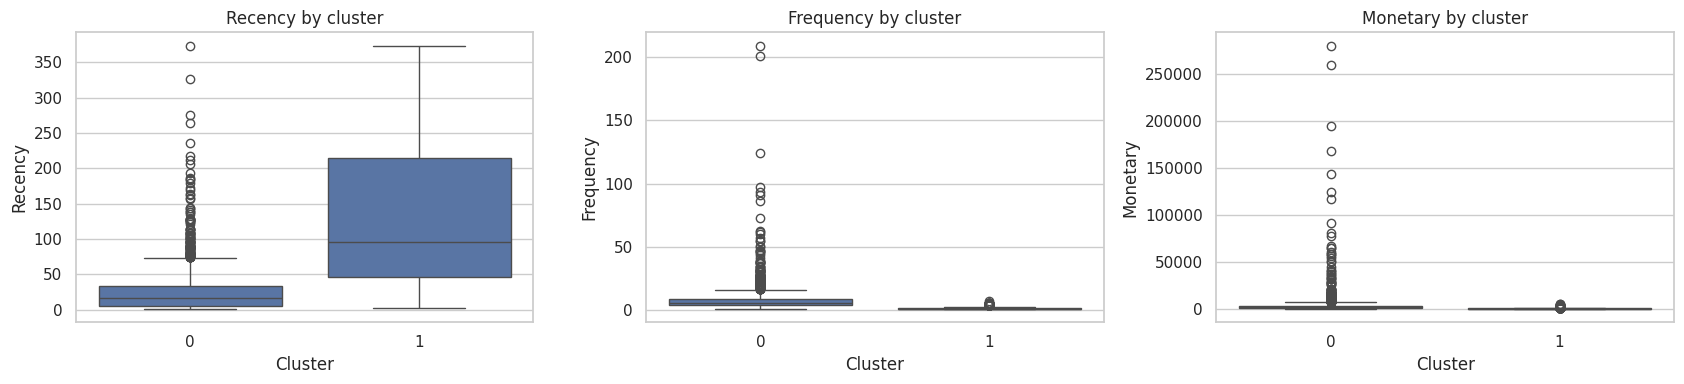

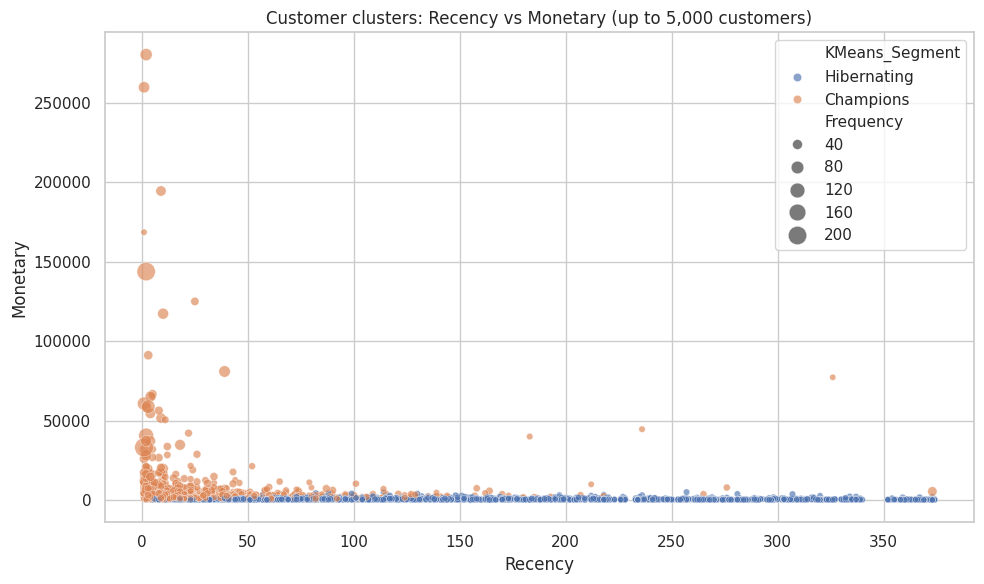

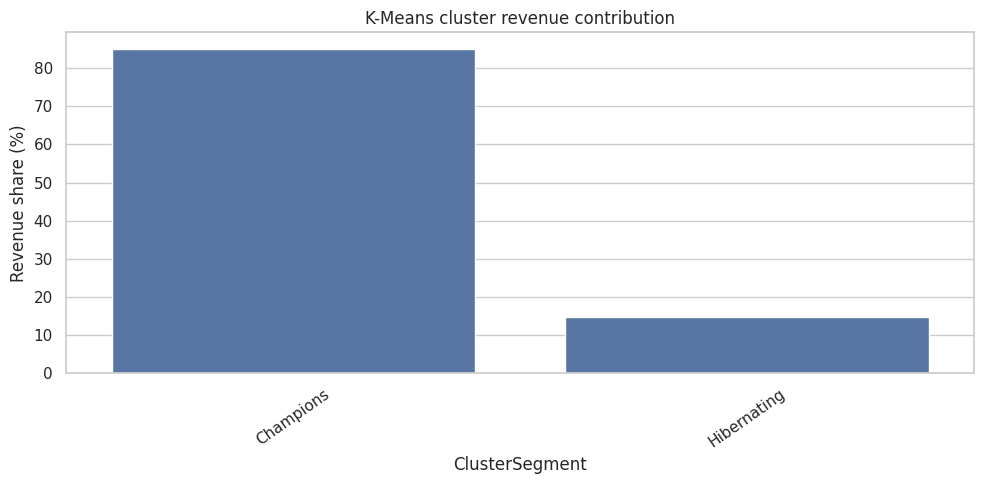

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.boxplot(data=rfm, x="Cluster", y=col, ax=ax)
    ax.set_title(f"{col} by cluster")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kmeans_rfm_cluster_boxplots.png", dpi=160, bbox_inches="tight")
plt.show()

sample = rfm.sample(min(5000, len(rfm)), random_state=RANDOM_STATE)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="Recency", y="Monetary",
                hue="KMeans_Segment", size="Frequency",
                sizes=(20, 180), alpha=0.65)
plt.title("Customer clusters: Recency vs Monetary (up to 5,000 customers)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kmeans_customer_scatter.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=cluster_profile, x="ClusterSegment", y="RevenueSharePct")
plt.title("K-Means cluster revenue contribution")
plt.ylabel("Revenue share (%)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kmeans_revenue_contribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Compare RFM scoring segments with K-Means

In [35]:
segment_comparison = pd.crosstab(
    rfm["RFM_Segment"], rfm["KMeans_Segment"], normalize="index"
) * 100
display(segment_comparison.round(1))
segment_comparison.to_csv(OUTPUT_DIR / "rfm_vs_kmeans_segment_comparison.csv")

KMeans_Segment,Champions,Hibernating
RFM_Segment,,
At Risk,13.800,86.200
Big Spenders,62.700,37.300
Champions,100.000,0.000
Hibernating,0.000,100.000
Loyal Customers,79.200,20.800
Needs Attention,0.200,99.800
Potential Loyalists,19.800,80.200


## 15. Generate business insights

In [36]:
print("CUSTOMER SEGMENTATION SUMMARY")
print("=" * 55)
print(f"Customers analyzed: {rfm['CustomerID'].nunique():,}")
print(f"Positive-sales revenue: GBP {rfm['Monetary'].sum():,.2f}")
print(f"Number of clusters: {FINAL_K}")
print(f"Silhouette score: {final_silhouette:.4f}\n")

for _, row in cluster_profile.sort_values("RevenueSharePct", ascending=False).iterrows():
    print(
        f"{row['ClusterSegment']} (cluster {int(row['Cluster'])}): "
        f"{int(row['Customers']):,} customers ({row['CustomerSharePct']:.1f}%); "
        f"GBP {row['TotalRevenue']:,.2f} revenue ({row['RevenueSharePct']:.1f}%); "
        f"avg recency {row['AvgRecency']:.1f} days; "
        f"frequency {row['AvgFrequency']:.1f}; "
        f"monetary GBP {row['AvgMonetary']:,.2f}"
    )

print("\nSuggested marketing actions (validate against the profile table):")
print("- Champions: loyalty rewards, early access and referral campaigns.")
print("- Loyal Customers: cross-sell and repeat-purchase campaigns.")
print("- Big Spenders: premium recommendations and personalized service.")
print("- Potential Loyalists: encourage a second or third purchase.")
print("- At Risk: targeted win-back campaigns.")
print("- Hibernating: low-cost reactivation; avoid overspending.")
print("- Needs Attention: targeted offers based on customer value.")

CUSTOMER SEGMENTATION SUMMARY
Customers analyzed: 4,338
Positive-sales revenue: GBP 8,887,208.89
Number of clusters: 2
Silhouette score: 0.4325

Champions (cluster 0): 1,668 customers (38.5%); GBP 7,565,611.80 revenue (85.1%); avg recency 26.5 days; frequency 8.4; monetary GBP 4,535.74
Hibernating (cluster 1): 2,670 customers (61.5%); GBP 1,321,597.09 revenue (14.9%); avg recency 134.7 days; frequency 1.7; monetary GBP 494.98

Suggested marketing actions (validate against the profile table):
- Champions: loyalty rewards, early access and referral campaigns.
- Loyal Customers: cross-sell and repeat-purchase campaigns.
- Big Spenders: premium recommendations and personalized service.
- Potential Loyalists: encourage a second or third purchase.
- At Risk: targeted win-back campaigns.
- Hibernating: low-cost reactivation; avoid overspending.
- Needs Attention: targeted offers based on customer value.


In [37]:
recommendations = pd.DataFrame([
    ["Champions", "Loyalty rewards, referrals and early access"],
    ["Loyal Customers", "Cross-selling and repeat purchase campaigns"],
    ["Big Spenders", "Premium offers and personalized recommendations"],
    ["Potential Loyalists", "Encourage repeat purchases"],
    ["At Risk", "Targeted win-back campaigns"],
    ["Hibernating", "Low-cost reactivation campaigns"],
    ["Needs Attention", "Personalized offers based on customer value"]
], columns=["Customer Segment", "Recommended Strategy"])

display(recommendations)
recommendations.to_csv(
    OUTPUT_DIR / "business_recommendations.csv", index=False
)

,Customer Segment,Recommended Strategy
0,Champions,"Loyalty rewards, referrals and early access"
1,Loyal Customers,Cross-selling and repeat purchase campaigns
2,Big Spenders,Premium offers and personalized recommendations
3,Potential Loyalists,Encourage repeat purchases
4,At Risk,Targeted win-back campaigns
5,Hibernating,Low-cost reactivation campaigns
6,Needs Attention,Personalized offers based on customer value


## 16. SQL: create a SQLite database

In [41]:
DB_PATH = OUTPUT_DIR / "customer_segmentation.db"
conn = sqlite3.connect(DB_PATH)

sql_transactions = retail.copy()
sql_transactions["InvoiceDate"] = sql_transactions["InvoiceDate"].astype(str)
sql_customer = rfm.copy()
sql_customer["FirstPurchase"] = sql_customer["FirstPurchase"].astype(str)
sql_customer["LastPurchase"] = sql_customer["LastPurchase"].astype(str)

sql_transactions.to_sql("retail_transactions", conn, if_exists="replace", index=False)
sql_customer.to_sql("customer_rfm", conn, if_exists="replace", index=False)
rfm_segment_summary.to_sql("rfm_segment_summary", conn, if_exists="replace", index=False)
cluster_profile.to_sql("kmeans_cluster_summary", conn, if_exists="replace", index=False)

print("SQLite database created:", DB_PATH)

SQLite database created: /content/drive/MyDrive/AB testing/phase_4_to_6_outputs/customer_segmentation.db


## 17. Run SQL business analysis queries

In [42]:
queries = {
    "Revenue and customers by K-Means segment": '''
        SELECT KMeans_Segment,
               COUNT(DISTINCT CustomerID) AS customers,
               ROUND(SUM(Monetary), 2) AS revenue,
               ROUND(100.0 * SUM(Monetary) /
                     (SELECT SUM(Monetary) FROM customer_rfm), 2) AS revenue_share_pct
        FROM customer_rfm
        GROUP BY KMeans_Segment
        ORDER BY revenue DESC;
    ''',
    "Top 10 customers by spend": '''
        SELECT CustomerID, Recency, Frequency, ROUND(Monetary, 2) AS Monetary,
               KMeans_Segment
        FROM customer_rfm
        ORDER BY Monetary DESC
        LIMIT 10;
    ''',
    "Top countries by revenue": '''
        SELECT Country, COUNT(DISTINCT CustomerID) AS customers,
               ROUND(SUM(Monetary), 2) AS revenue
        FROM customer_rfm
        GROUP BY Country
        ORDER BY revenue DESC
        LIMIT 10;
    ''',
    "Highest-value at-risk customers": '''
        SELECT CustomerID, Recency, Frequency,
           ROUND(Monetary, 2) AS Monetary,
           RFM_Segment
        FROM customer_rfm
        WHERE RFM_Segment = 'At Risk'
        ORDER BY Monetary DESC
        LIMIT 20;
    '''
}

for title, query in queries.items():
    print("\n" + title.upper())
    print("-" * len(title))
    display(pd.read_sql_query(query, conn))


REVENUE AND CUSTOMERS BY K-MEANS SEGMENT
----------------------------------------


,KMeans_Segment,customers,revenue,revenue_share_pct
0,Champions,1668,"7,565,611.800",85.130
1,Hibernating,2670,"1,321,597.090",14.870



TOP 10 CUSTOMERS BY SPEND
-------------------------


,CustomerID,Recency,Frequency,Monetary,KMeans_Segment
0,14646,2,73,"280,206.020",Champions
1,18102,1,60,"259,657.300",Champions
2,17450,9,46,"194,390.790",Champions
3,16446,1,2,"168,472.500",Champions
4,14911,2,201,"143,711.170",Champions
5,12415,25,21,"124,914.530",Champions
6,14156,10,55,"117,210.080",Champions
7,17511,3,31,"91,062.380",Champions
8,16029,39,63,"80,850.840",Champions
9,12346,326,1,"77,183.600",Champions



TOP COUNTRIES BY REVENUE
------------------------


,Country,customers,revenue
0,United Kingdom,3920,"7,285,024.640"
1,Netherlands,9,"285,446.340"
2,EIRE,3,"265,262.460"
3,Germany,94,"228,678.400"
4,France,87,"208,934.310"
5,Australia,9,"139,843.950"
6,Spain,29,"62,821.160"
7,Switzerland,20,"56,419.290"
8,Belgium,24,"41,551.260"
9,Sweden,8,"38,367.830"



HIGHEST-VALUE AT-RISK CUSTOMERS
-------------------------------


,CustomerID,Recency,Frequency,Monetary,RFM_Segment
0,12346,326,1,"77,183.600",At Risk
1,15749,236,3,"44,534.300",At Risk
2,15098,183,3,"39,916.500",At Risk
3,12409,79,3,"11,072.670",At Risk
4,16180,101,8,"10,254.180",At Risk
5,12590,212,2,"9,864.260",At Risk
6,13093,276,8,"7,832.470",At Risk
7,12435,80,2,"7,829.890",At Risk
8,12980,158,9,"7,374.900",At Risk
9,16745,87,17,"7,180.700",At Risk


## 18. Export reusable SQL queries

In [43]:
sql_script = """
-- Revenue and customers by K-Means segment
SELECT KMeans_Segment,
       COUNT(DISTINCT CustomerID) AS customers,
       ROUND(SUM(Monetary), 2) AS revenue
FROM customer_rfm
GROUP BY KMeans_Segment
ORDER BY revenue DESC;

-- Top 10 customers by spend
SELECT CustomerID, Recency, Frequency,
       Monetary, RFM_Segment
FROM customer_rfm
ORDER BY Monetary DESC
LIMIT 10;

-- Highest-value at-risk customers
SELECT CustomerID, Recency, Frequency,
       ROUND(Monetary, 2) AS Monetary
FROM customer_rfm
WHERE RFM_Segment = 'At Risk'
ORDER BY Monetary DESC
LIMIT 20;
"""

(OUTPUT_DIR / "business_analysis.sql").write_text(
    sql_script, encoding="utf-8"
)

conn.close()
print("SQL script exported.")

SQL script exported.


## 19. Export Tableau-ready datasets

Use these CSVs as data sources in Tableau. They support KPI cards, segment comparisons, revenue contribution, customer drill-down and time trends.

Suggested dashboard sheets:
1. **Executive Overview:** customer count, revenue, average order value, selected K and silhouette score.
2. **RFM Segmentation:** customer count and revenue by RFM segment.
3. **K-Means Segmentation:** cluster size, revenue share and average R/F/M.
4. **Customer Explorer:** customer-level RFM values, labels and country.
5. **Sales Trends:** monthly revenue, orders and customers.

Keep the A/B testing dashboard separate. The marketing experiment users and Online Retail customers are from different datasets and must not be joined.

In [44]:
# Customer-level source
rfm.to_csv(OUTPUT_DIR / "tableau_customer_segments.csv", index=False)

# Segment and cluster summary sources
rfm_segment_summary.to_csv(OUTPUT_DIR / "tableau_rfm_segment_summary.csv", index=False)
cluster_profile.to_csv(OUTPUT_DIR / "tableau_kmeans_cluster_summary.csv", index=False)
k_evaluation.to_csv(OUTPUT_DIR / "tableau_k_selection_metrics.csv", index=False)

# Monthly sales source
retail["InvoiceMonth"] = retail["InvoiceDate"].dt.to_period("M").astype(str)
monthly_sales = retail.groupby("InvoiceMonth").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Customers=("CustomerID", "nunique")
).reset_index()
monthly_sales.to_csv(OUTPUT_DIR / "tableau_monthly_sales.csv", index=False)

# Country sales source
country_summary = retail.groupby("Country").agg(
    Revenue=("Revenue", "sum"),
    Customers=("CustomerID", "nunique"),
    Orders=("InvoiceNo", "nunique")
).reset_index().sort_values("Revenue", ascending=False)
country_summary.to_csv(OUTPUT_DIR / "tableau_country_summary.csv", index=False)

# Field definitions
data_dictionary = pd.DataFrame([
    ["CustomerID", "Unique customer identifier"],
    ["Recency", "Days since latest purchase at the analysis snapshot date"],
    ["Frequency", "Number of distinct invoices/orders"],
    ["Monetary", "Total positive-sales revenue in GBP"],
    ["R_Score", "Recency quintile score; 5 is most recent"],
    ["F_Score", "Frequency quintile score; 5 is highest frequency"],
    ["M_Score", "Monetary quintile score; 5 is highest spend"],
    ["RFM_Segment", "Rule-based segment from R/F/M quintile scores"],
    ["Cluster", "K-Means cluster ID; numeric IDs are arbitrary"],
    ["KMeans_Segment", "Descriptive name assigned from cluster RFM profile"],
    ["CustomerSharePct", "Percentage of customers in a segment/cluster"],
    ["RevenueSharePct", "Percentage of analyzed revenue in a segment/cluster"]
], columns=["Field", "Definition"])
data_dictionary.to_csv(OUTPUT_DIR / "data_dictionary.csv", index=False)

print("Tableau exports:")
for p in sorted(OUTPUT_DIR.glob("tableau_*.csv")):
    print("-", p.name)

Tableau exports:
- tableau_country_summary.csv
- tableau_customer_segments.csv
- tableau_k_selection_metrics.csv
- tableau_kmeans_cluster_summary.csv
- tableau_monthly_sales.csv
- tableau_rfm_segment_summary.csv


## 20. Write project summary and package all deliverables

In [45]:
summary_text = f'''
CUSTOMER SEGMENTATION PROJECT SUMMARY
=====================================
Snapshot date: {snapshot_date.date()}
Transaction rows analyzed: {len(retail):,}
Unique customers analyzed: {len(rfm):,}
Total positive-sales revenue: GBP {rfm["Monetary"].sum():,.2f}

RFM definitions:
- Recency: days since latest purchase
- Frequency: distinct invoice count
- Monetary: total positive transaction revenue

K-Means:
- Selected K: {FINAL_K}
- Silhouette score: {final_silhouette:.4f}
- Features: log1p(Recency), log1p(Frequency), log1p(Monetary)
- Scaling: StandardScaler
- Random state: {RANDOM_STATE}

Interpretation notes:
- RFM segments are rule-based quintile groups.
- K-Means cluster IDs are arbitrary.
- Cluster names describe relative cluster profiles.
- Historical patterns do not prove that a marketing action caused customer behaviour.
- Monetary values are in GBP.
'''
(OUTPUT_DIR / "project_summary.txt").write_text(summary_text, encoding="utf-8")
print(summary_text)

zip_path = "/content/customer_segmentation_phase4_to_6_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in OUTPUT_DIR.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=p.relative_to(OUTPUT_DIR))

print("Created ZIP:", zip_path)
files.download(zip_path)


CUSTOMER SEGMENTATION PROJECT SUMMARY
Snapshot date: 2011-12-10
Transaction rows analyzed: 392,692
Unique customers analyzed: 4,338
Total positive-sales revenue: GBP 8,887,208.89

RFM definitions:
- Recency: days since latest purchase
- Frequency: distinct invoice count
- Monetary: total positive transaction revenue

K-Means:
- Selected K: 2
- Silhouette score: 0.4325
- Features: log1p(Recency), log1p(Frequency), log1p(Monetary)
- Scaling: StandardScaler
- Random state: 42

Interpretation notes:
- RFM segments are rule-based quintile groups.
- K-Means cluster IDs are arbitrary.
- Cluster names describe relative cluster profiles.
- Historical patterns do not prove that a marketing action caused customer behaviour.
- Monetary values are in GBP.

Created ZIP: /content/customer_segmentation_phase4_to_6_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>